In [51]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

path = str(Path(Path('thermo.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

# Lucas notebook

import xarray as xa
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm

from tools.cbook import pickle2Obj, interp_z, compute_thetae
from tools.FV3_tools import read_solo_fields

large = 16; med = 12; small = 10
params = {'axes.titlesize': large,
          'legend.fontsize': med,
          'figure.figsize': (8, 4),
          'axes.labelsize': med,
          'axes.titlesize': large,
          'xtick.labelsize': small,
          'ytick.labelsize': small,
          'figure.titlesize': large,
          'axes.titlepad': 6}
plt.rcParams.update(params)


file = '/work/wicker/climate_runs/FV3_Solo/bubble/euler64/3km/QV14/atmos_hifreq.nc'

ds = xa.open_dataset(file,decode_times=False,chunks={'time': 1})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


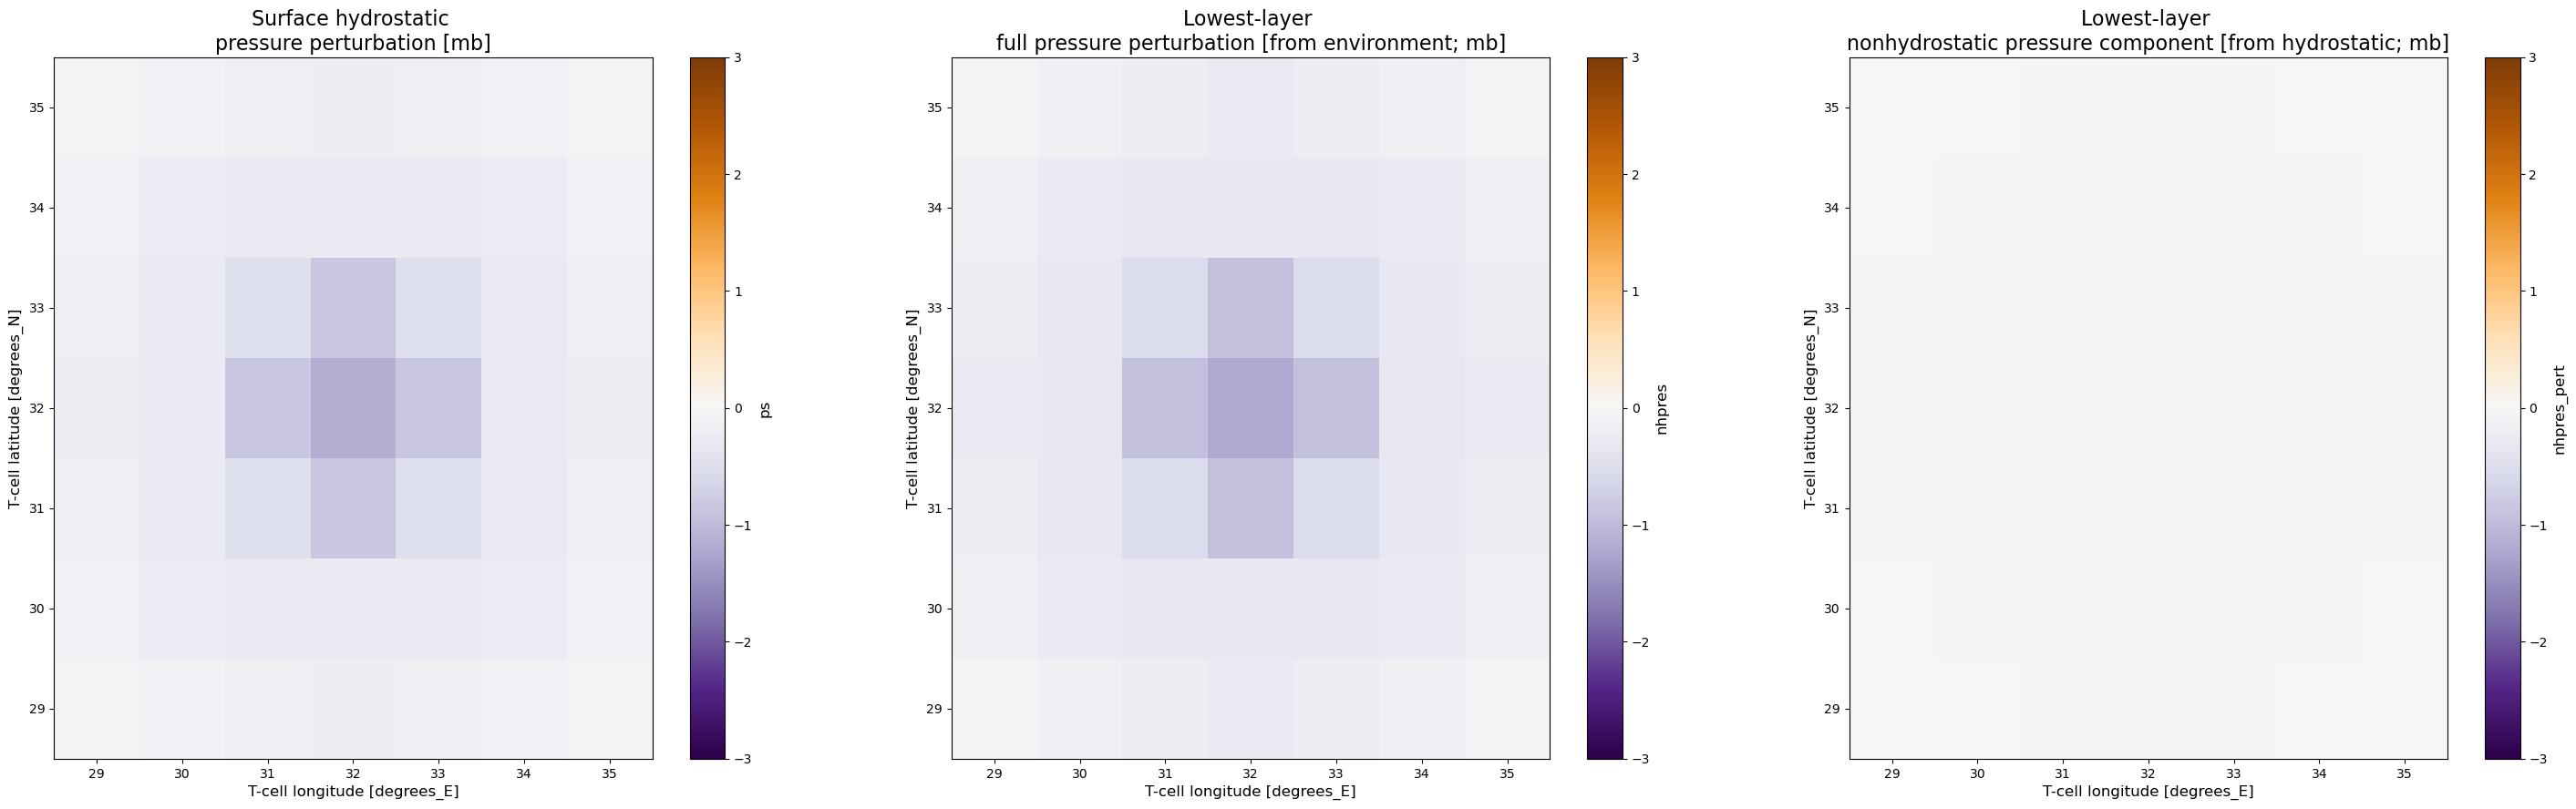

In [52]:
t = 10

xcoord = [28,35]
ycoord = [28,35]

ds_small=ds.isel(time=t,grid_xt=slice(28,35),grid_yt=slice(28,35))

ds_ref=ds.isel(time=0,grid_xt=0,grid_yt=0)

fig=plt.figure(figsize=(36,10))
ax = fig.add_subplot(1,3,1)
((ds_small.ps-ds_ref.ps)/1.e2).plot(ax=ax,vmax=3,vmin=-3,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Surface hydrostatic \npressure perturbation [mb]")
ax = fig.add_subplot(1,3,2)
( (ds_small.nhpres[-1,:,:]-ds_ref.nhpres[-1])/1.e2).plot(ax=ax,vmax=3,vmin=-3,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Lowest-layer \nfull pressure perturbation [from environment; mb]")
ax = fig.add_subplot(1,3,3)
( (ds_small.nhpres_pert[-1,:,:])/1.e2).plot(ax=ax,vmax=3,vmin=-3,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Lowest-layer \nnonhydrostatic pressure component [from hydrostatic; mb]");

Text(0.5, 1.0, 'Perturbation column total water component [mb]')

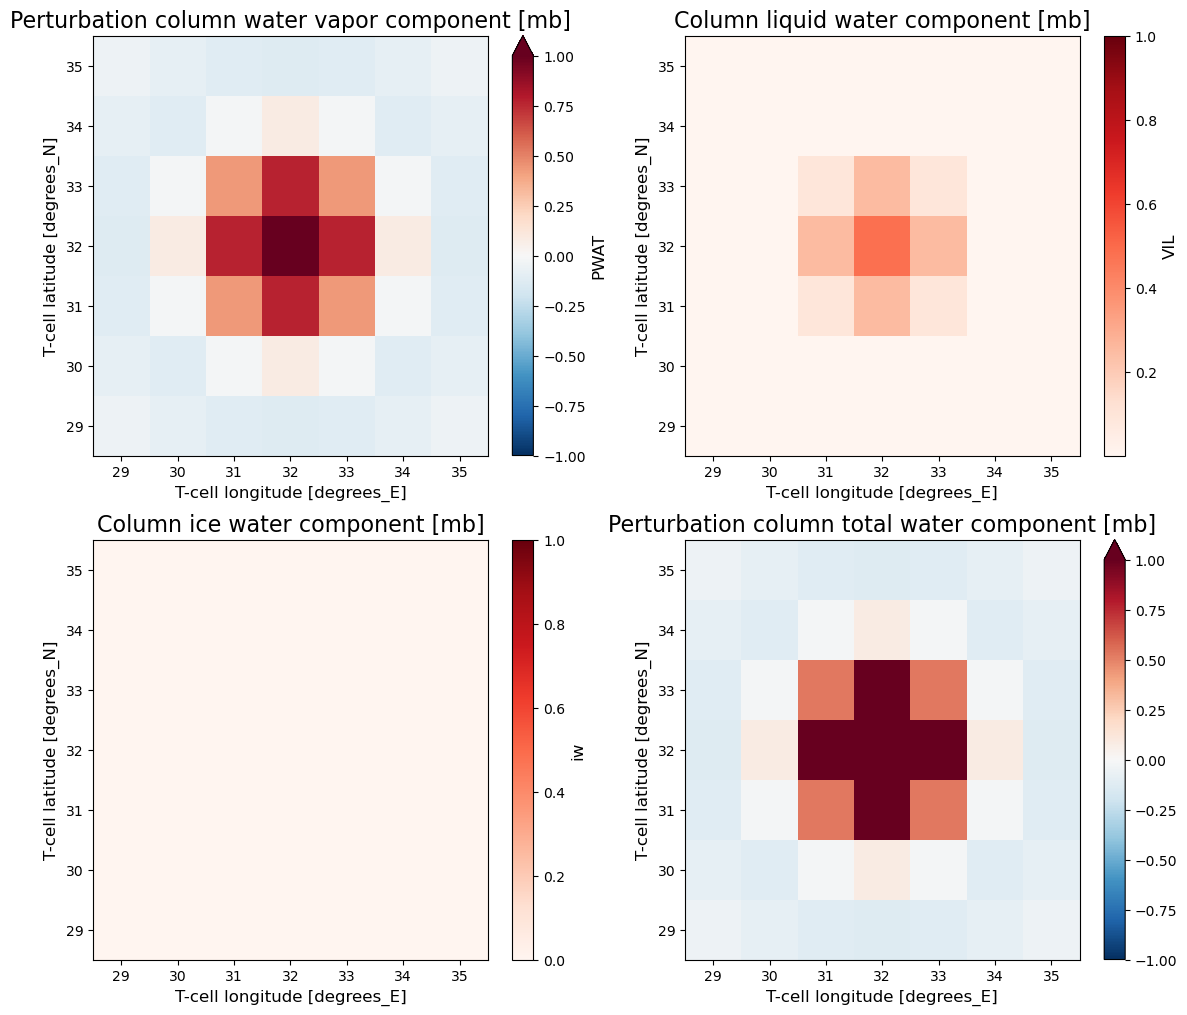

In [53]:
#Mass Components (note PWAT, VIL, IW all in units of kg/m**2 so conversion is easy)

grav = 9.81 #m/s
Mv = ds_small.PWAT*grav/100. - ds_ref.PWAT*grav/100.
Ml = ds_small.VIL*grav/100.
Mi = ds_small.iw*grav/100.

fig = plt.figure(figsize=(14,12))
ax = fig.add_subplot(2,2,1)
(Mv).plot(ax=ax,vmax=1,vmin=-1,cmap=plt.get_cmap('RdBu_r'))
ax.set_title("Perturbation column water vapor component [mb]")

ax = fig.add_subplot(2,2,2)
Ml.plot(ax=ax,vmax=1,cmap=plt.get_cmap('Reds'))
ax.set_title("Column liquid water component [mb]")

ax = fig.add_subplot(2,2,3)
Mi.plot(ax=ax,vmax=1,cmap=plt.get_cmap('Reds'))
ax.set_title("Column ice water component [mb]")

ax = fig.add_subplot(2,2,4)
(Mv + Ml + Mi).plot(ax=ax,vmax=1,vmin=-1,cmap=plt.get_cmap('RdBu_r'))
ax.set_title("Perturbation column total water component [mb]")

In [54]:
phalf = ds_small.phalf
ptop=phalf[0]
phalf=phalf[1:]
phyd=ds_small.delp.sum(dim="pfull") + ptop
phyd_ref=ds_ref.delp.sum(dim="pfull") + ptop
psphum=((ds_small.sphum)*ds_small.delp).sum(dim="pfull")
psphum_ref=((ds_ref.sphum)*ds_ref.delp).sum(dim="pfull")

#qp and qn are **weight** per grid cell and not specific ratios
pcond=((ds_small.qp + ds_small.qn)).sum(dim="pfull")

In [55]:
ds_small

<xarray.Dataset> Size: 169kB
Dimensions:       (grid_xt: 7, grid_yt: 7, pfull: 50, phalf: 51)
Coordinates:
  * grid_xt       (grid_xt) float64 56B 29.0 30.0 31.0 32.0 33.0 34.0 35.0
  * grid_yt       (grid_yt) float64 56B 29.0 30.0 31.0 32.0 33.0 34.0 35.0
    time          float64 8B 660.0
  * pfull         (pfull) float64 400B 22.22 26.98 32.08 ... 990.7 996.1 999.0
  * phalf         (phalf) float64 408B 20.0 24.61 29.51 ... 994.1 998.0 1e+03
Data variables: (12/27)
    PWAT          (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    VIL           (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    iw            (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    PRESsfc       (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    REFC          (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    REFD1km       (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    ...            ...
    rwmr          (pfull, grid_yt, grid_xt) float32 10kB dask.array<chunksize=(50, 7, 7), meta=np.ndarray>
    delz          (pfull, grid_yt, grid_xt) float32 10kB dask.array<chunksize=(50, 7, 7), meta=np.ndarray>
    ps            (grid_yt, grid_xt) float32 196B dask.array<chunksize=(7, 7), meta=np.ndarray>
    reflectivity  (pfull, grid_yt, grid_xt) float32 10kB dask.array<chunksize=(50, 7, 7), meta=np.ndarray>
    qp            (pfull, grid_yt, grid_xt) float32 10kB dask.array<chunksize=(50, 7, 7), meta=np.ndarray>
    qn            (pfull, grid_yt, grid_xt) float32 10kB dask.array<chunksize=(50, 7, 7), meta=np.ndarray>
Attributes:
    NumFilesInSet:  1
    title:          bubble.solo.bubble
    grid_type:      regular
    grid_tile:      N/A

In [56]:
#Calculate hydrostatic pressure on lower interfaces (note this is not layer mean)
#ds_cross=ds_small.sel(grid_xt=30)#,grid_xt=slice(50,70)) #farther away



ycross=32

ds_cross=ds_small.sel(grid_yt=ycross)#,grid_xt=slice(50,70)) #farther away

ptop=phalf[0]
phalf=phalf[1:]
xphyd=ds_cross.delp.cumsum(dim="pfull") + ptop
xphyd_ref=ds_ref.delp.cumsum(dim="pfull") + ptop
xpsphum=((ds_cross.sphum)*ds_cross.delp).cumsum(dim="pfull")
xpsphum_ref=((ds_ref.sphum)*ds_ref.delp).cumsum(dim="pfull")
xpcond=(ds_cross.qp + ds_cross.qn).cumsum(dim="pfull")


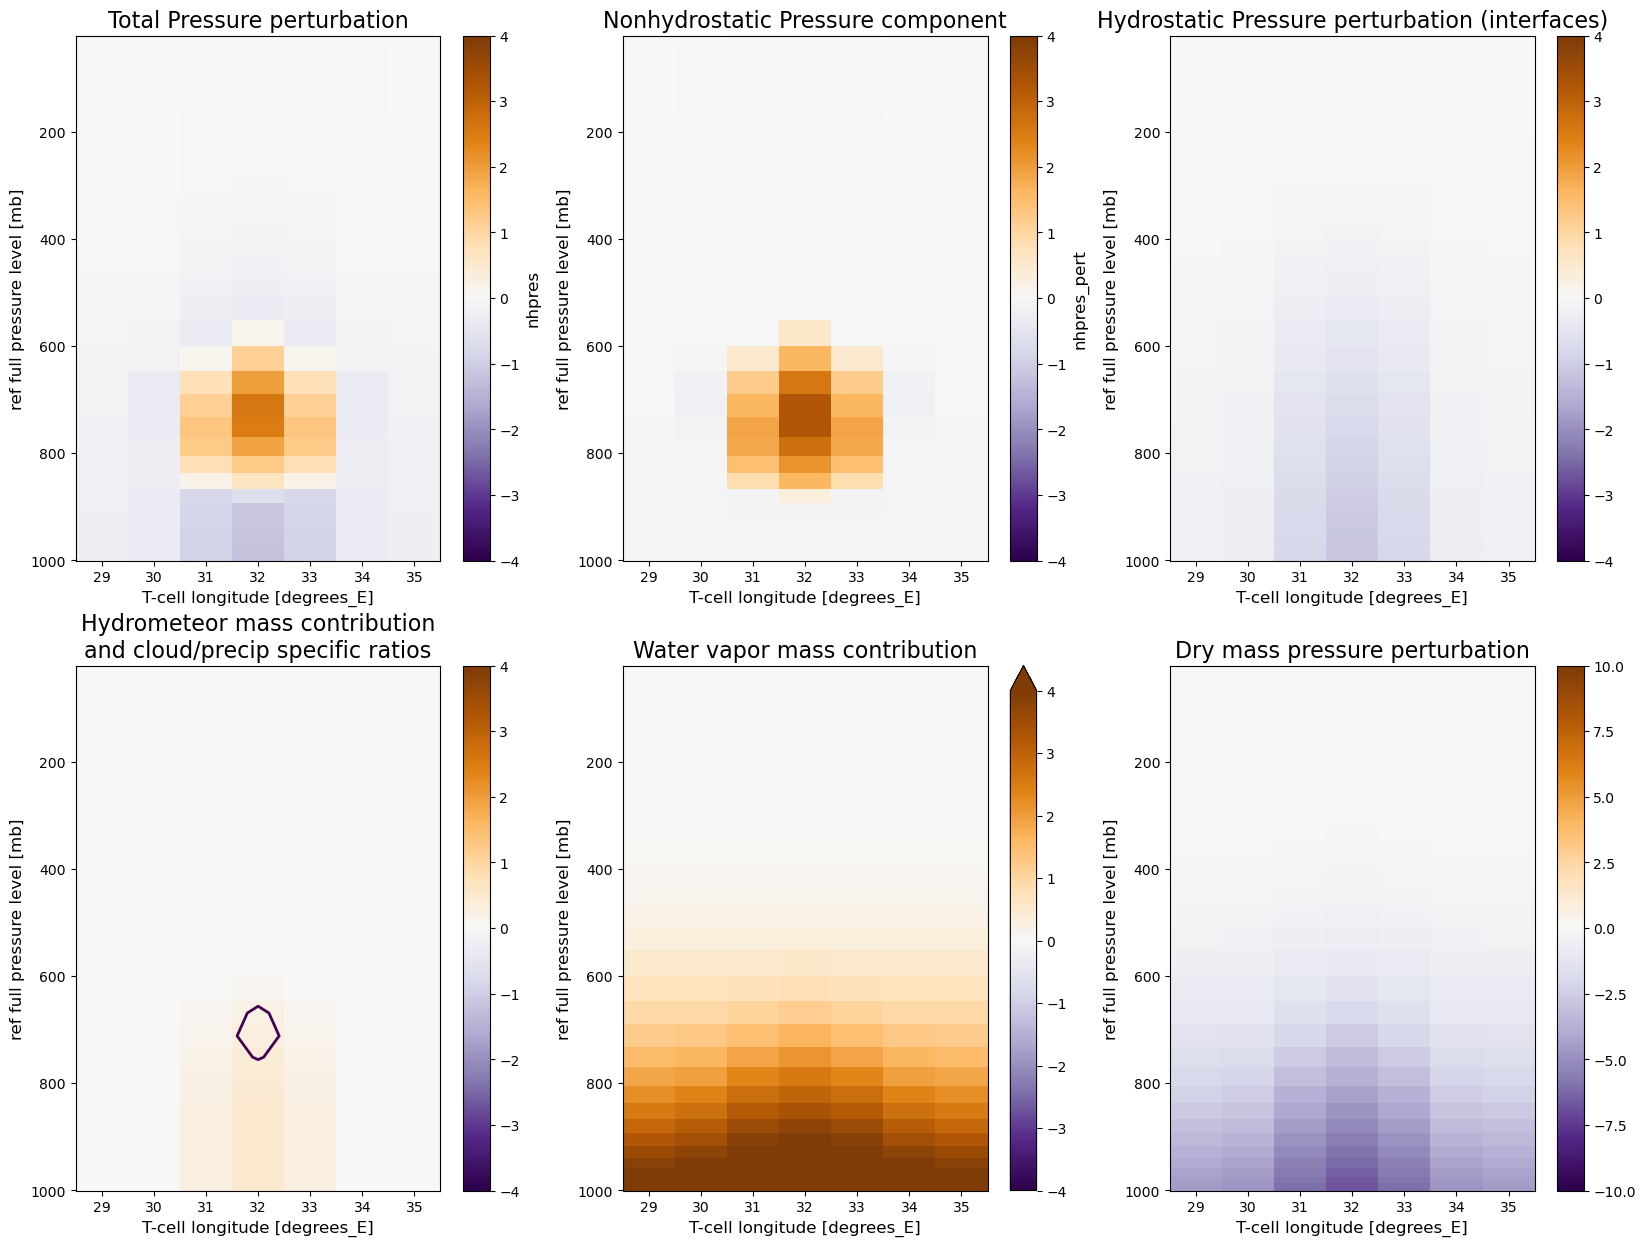

In [57]:
fig = plt.figure(figsize=(20,15))

#nhpres anom
ax = fig.add_subplot(2,3,1)
((ds_cross.nhpres-ds_ref.nhpres)/100).plot(ax=ax,yincrease=False,vmax=4,vmin=-4,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Total Pressure perturbation")

#nhpres_pert
ax = fig.add_subplot(2,3,2)
((ds_cross.nhpres_pert)/100.).plot(ax=ax,yincrease=False,vmax=4,vmin=-4,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Nonhydrostatic Pressure component")

ax = fig.add_subplot(2,3,3)
phyd=(ds_cross.nhpres-ds_ref.nhpres-ds_cross.nhpres_pert)
((xphyd-xphyd_ref)/100.).plot(ax=ax,yincrease=False,vmax=4,vmin=-4,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Hydrostatic Pressure perturbation (interfaces)")

#hydrometeors
ax = fig.add_subplot(2,3,4)
qq=np.cumsum(ds_cross.qp + ds_cross.qn,axis=0)
cloud=ds_cross.qn/ds_cross.delp*1000. #g/kg 
prec=ds_cross.qp/ds_cross.delp*1000.

(xpcond/100.).plot(ax=ax,yincrease=False,vmax=4,vmin=-4,cmap=plt.get_cmap('PuOr_r'))
vvc=cloud.plot.contour(ax=ax,yincrease=False,color='k',levels=np.arange(2,10,2),linewidths=2)
vvp=prec.plot.contour(ax=ax,yincrease=False,color='darkgreen',levels=np.arange(2,15,2),linewidths=2)
ax.set_title("Hydrometeor mass contribution\nand cloud/precip specific ratios")

ax = fig.add_subplot(2,3,5)
((xpsphum)/100.).plot(ax=ax,yincrease=False,vmax=4,vmin=-4,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Water vapor mass contribution");

#dry pressure perturbation
ax = fig.add_subplot(2,3,6)
((xphyd-xphyd_ref-xpcond-xpsphum)/100.).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Dry mass pressure perturbation");

# #NOTE: apparently this behavior will change in a future version of Matplotlib
# #  so if it makes empty plots then just remove it.
# for n in range(6):
#     ax = fig.add_subplot(2,3,n+1)
#     ax.set_xlabel("")

(7, 7)


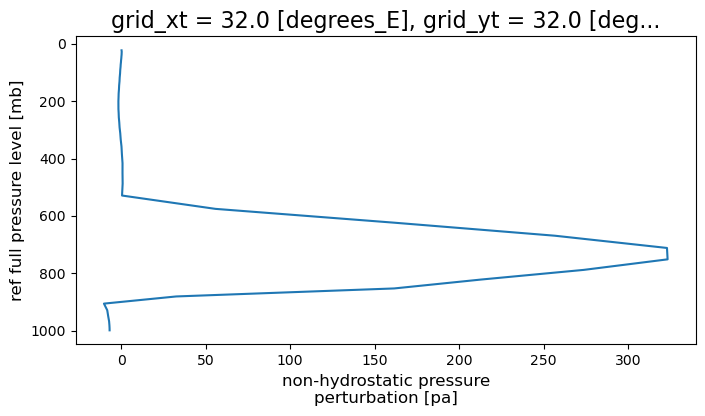

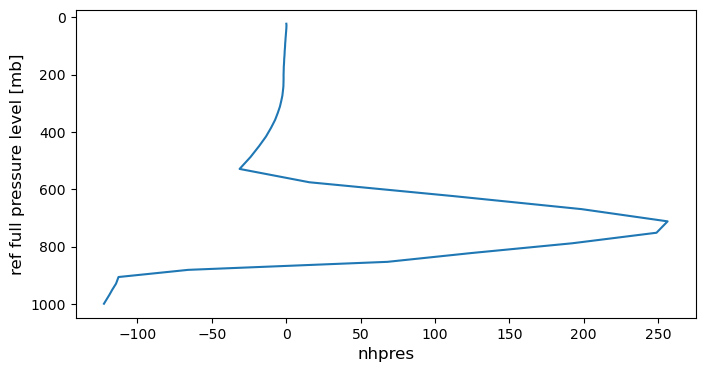

In [58]:
ds_cross.nhpres_pert.shape
phyd=ds_small.delp.sum(dim="pfull") + ptop
print(phyd.shape)

(ds_cross.nhpres_pert[:,3]).plot(y='pfull',yincrease=False)
plt.show()
((ds_cross.nhpres[:,3] - ds_ref.nhpres[:])).plot(y='pfull',yincrease=False)